# Case 3 — Part 2: Data-Driven Container Resource Optimization (ML Surrogate)

This notebook implements the **optimization phase** of Case 3, utilizing the pre-trained **Multi-Layer Perceptron (MLP)** neural network as a surrogate model to right-size container CPU and RAM under strict latency Service Level Agreements (SLAs).

---

### Core Comparison
- **Case 1 & 2:** Relied on theoretical M/M/1 queueing formulas:
  $$W = \frac{1}{\mu - \lambda} \le W_{\max} \iff \mu - \lambda \ge \frac{1}{W_{\max}}$$
- **Case 3:** Embeds the non-linear machine learning surrogate trained on real benchmark traces:
  $$\min_{\text{CPU}, \text{RAM}} \quad w_{\text{cpu}} \frac{\text{CPU}}{\text{CPU}_{\max}} + w_{\text{ram}} \frac{\text{RAM}}{\text{RAM}_{\max}}$$
  $$\text{s.t.} \quad \hat{W}_{\text{MLP}}(\text{CPU}, \text{RAM}, \lambda, \text{payload}) \le W_{\max}$$


In [1]:
import os
ASSETS_DIR = os.path.join("assets", "part3") if os.path.exists("assets") else os.path.join("..", "assets", "part3")
os.makedirs(ASSETS_DIR, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from container_ml_model import (
    load_artifacts,
    predict_latency,
    optimize_container_resources_ml,
    compare_ml_vs_queue_model,
    print_optimization_report,
)

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

# Load models and scaler trained in container_ml_training.ipynb
artifacts = load_artifacts()
if artifacts is None:
    raise FileNotFoundError("Pre-trained models not found. Please run container_ml_training.ipynb first.")

models, scaler, metrics = artifacts
mlp_model = models["mlp"]
print("Successfully loaded pre-trained models from models/:", list(models.keys()))
pd.DataFrame(metrics).T

Successfully loaded pre-trained models from models/: ['ridge', 'random_forest', 'mlp']


,r2,mae_ms,rmse_ms
ridge,0.635078,126.719840,389.703755
random_forest,0.999950,1.168940,4.551929
mlp,0.953556,50.433379,139.026990


## 1. Visualizing the Learned Latency Response Surface (MLP)

We query the MLP surrogate across the entire allowable container configuration space:
- $\text{CPU} \in [100, 1000]\text{ mCPU}$
- $\text{RAM} \in [64, 512]\text{ MB}$

This reveals the non-linear latency landscape, showing where the container is safe vs. where it enters CPU starvation.


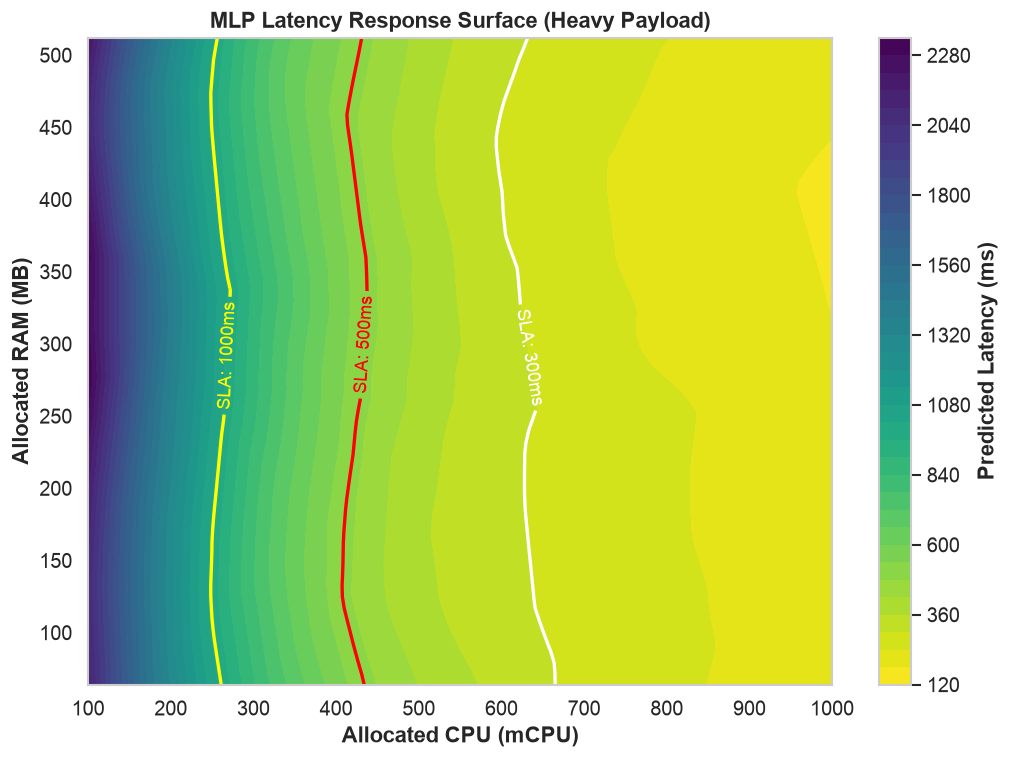

In [2]:
cpu_vals = np.linspace(100, 1000, 60)
ram_vals = np.linspace(64, 512, 60)
CPU_grid, RAM_grid = np.meshgrid(cpu_vals, ram_vals)

pred_latencies = predict_latency(
    model=mlp_model,
    scaler=scaler,
    cpu_mcpu=CPU_grid.ravel(),
    ram_mb=RAM_grid.ravel(),
    rps=np.full(CPU_grid.size, 1.0),
    is_heavy_payload=np.full(CPU_grid.size, 1),
).reshape(CPU_grid.shape)

plt.figure(figsize=(10, 7))
contour = plt.contourf(CPU_grid, RAM_grid, pred_latencies, levels=35, cmap="viridis_r")
cbar = plt.colorbar(contour)
cbar.set_label("Predicted Latency (ms)", fontweight="bold")

# Contour lines for standard SLA boundaries
sla_lines = plt.contour(CPU_grid, RAM_grid, pred_latencies, levels=[300.0, 500.0, 1000.0], colors=["white", "red", "yellow"], linewidths=2)
plt.clabel(sla_lines, inline=True, fmt={300.0: "SLA: 300ms", 500.0: "SLA: 500ms", 1000.0: "SLA: 1000ms"}, fontsize=11)

plt.title("MLP Latency Response Surface (Heavy Payload)", fontweight="bold")
plt.xlabel("Allocated CPU (mCPU)", fontweight="bold")
plt.ylabel("Allocated RAM (MB)", fontweight="bold")
plt.savefig(os.path.join(ASSETS_DIR, "07_mlp_latency_contour_surface.png"), dpi=150, bbox_inches="tight")
plt.show()

## 2. Solving the Data-Driven Resource Optimization Problem

Under an SLA of $W_{\max} = 500\text{ ms}$, we find the optimal $(\text{CPU}^*, \text{RAM}^*)$ that minimizes the hardware cost while satisfying $\hat{W}_{\text{MLP}} \le 500\text{ ms}$.



  CASE 3: DATA-DRIVEN CONTAINER RESOURCE OPTIMIZATION (Surrogate: MLP)
Workload, SLA & Surrogate Optimization Parameters:
  Workload (lambda)             : 1.00 requests/sec
  Payload Type                  : Heavy (CPU/IO bound, payload=1)
  Target Latency SLA (W_max)    : 500.00 ms (0.5000 s)
  ML Surrogate Model            : MLP
  Optimization Search Method    : adaptive_grid
  CPU Allocation Bounds         : [100, 1000] millicores
  RAM Allocation Bounds         : [64, 512] MB
  Objective Weights (CPU, RAM)  : w_cpu=1.00, w_ram=1.00
  Feasibility Status            : Optimal
************************************************************************
  OPTIMAL SOLUTION FOUND
************************************************************************
Optimal Resource Allocation:
  Optimal CPU Allocation        : 440.0 mCPU (bounds: [100, 1000])
  Optimal RAM Allocation        : 64.0 MB (bounds: [64, 512])
------------------------------------------------------------------------
ML Surrogate 

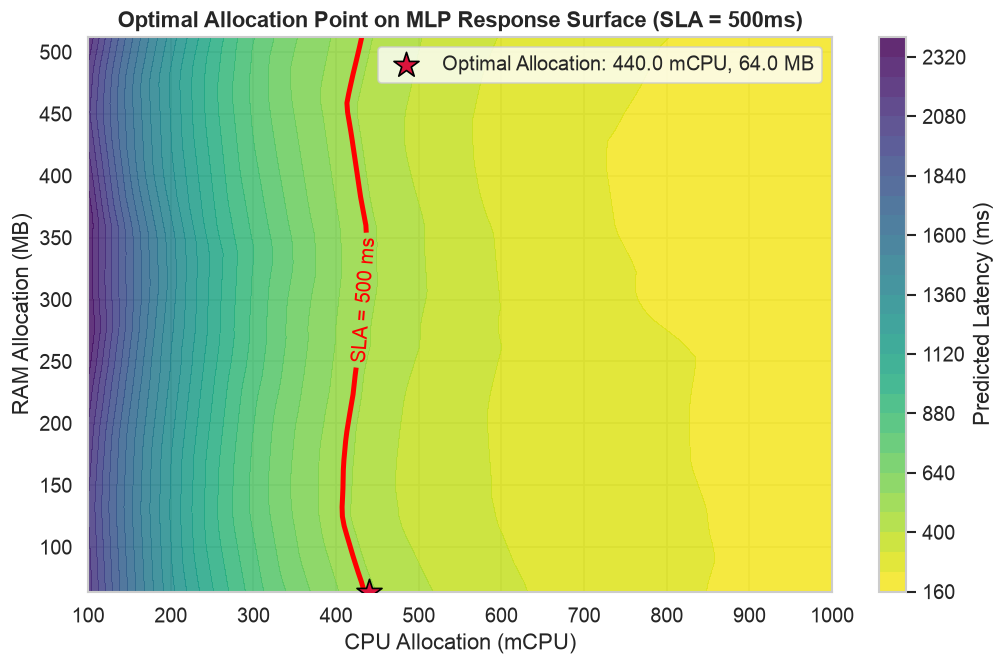

In [3]:
opt_result = optimize_container_resources_ml(
    lambda_req=1.0,
    w_max_ms=500.0,
    model=mlp_model,
    scaler=scaler,
    is_heavy_payload=1,
)

print_optimization_report(opt_result, model_name="MLP")

print("=" * 55)
print("   OPTIMAL CONTAINER RESOURCE ALLOCATION (MLP)")
print("=" * 55)
for k, v in opt_result.items():
    print(f"{k:<25}: {v}")
print("=" * 55)

# Plot optimal point on the response surface
plt.figure(figsize=(10, 6))
plt.contourf(CPU_grid, RAM_grid, pred_latencies, levels=30, cmap="viridis_r", alpha=0.85)
cbar = plt.colorbar()
cbar.set_label("Predicted Latency (ms)")

sla_c = plt.contour(CPU_grid, RAM_grid, pred_latencies, levels=[500.0], colors=["red"], linewidths=3)
plt.clabel(sla_c, inline=True, fmt="SLA = 500 ms", fontsize=12)

plt.scatter(
    [opt_result["cpu_optimal"]],
    [opt_result["ram_optimal"]],
    color="crimson",
    s=250,
    marker="*",
    edgecolor="black",
    zorder=5,
    label=f"Optimal Allocation: {opt_result['cpu_optimal']} mCPU, {opt_result['ram_optimal']} MB"
)
plt.title("Optimal Allocation Point on MLP Response Surface (SLA = 500ms)", fontweight="bold")
plt.xlabel("CPU Allocation (mCPU)")
plt.ylabel("RAM Allocation (MB)")
plt.legend(loc="upper right", frameon=True)
plt.savefig(os.path.join(ASSETS_DIR, "08_optimal_sizing_contour.png"), dpi=150, bbox_inches="tight")
plt.show()

## 3. SLA Sensitivity Analysis: Stricter Latency Requirements

How does the optimal resource sizing scale as SLA requirements become progressively more stringent ($W_{\max} \downarrow$)?


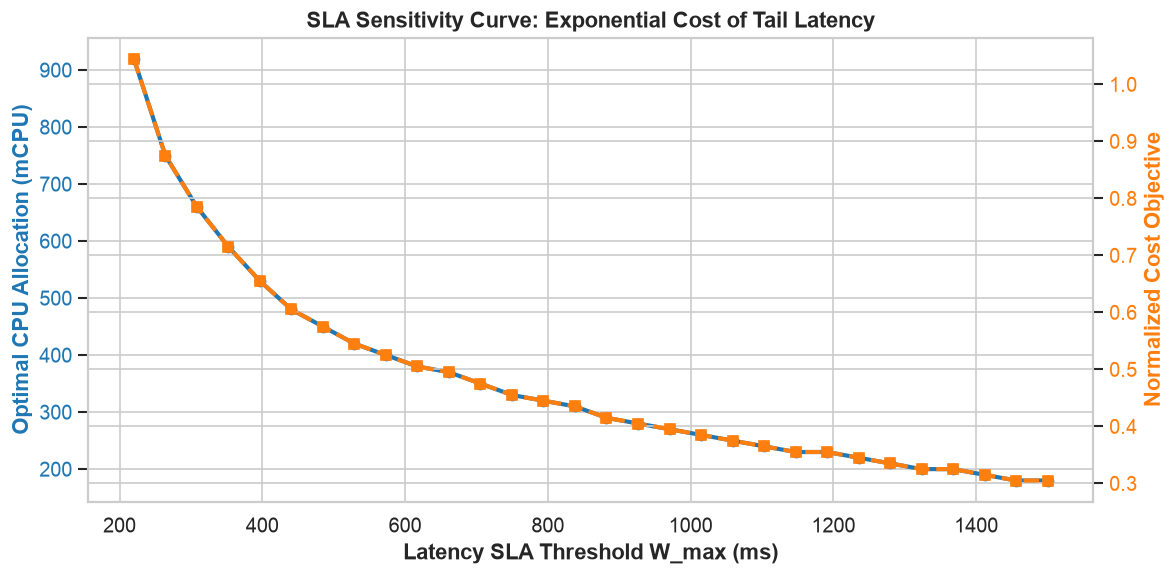

In [4]:
sla_range = np.linspace(220.0, 1500.0, 30)
records = []

for w in sla_range:
    res = optimize_container_resources_ml(
        lambda_req=1.0,
        w_max_ms=w,
        model=mlp_model,
        scaler=scaler,
        is_heavy_payload=1
    )
    if res["feasible"]:
        records.append({
            "SLA_ms": w,
            "CPU_mCPU": res["cpu_optimal"],
            "RAM_MB": res["ram_optimal"],
            "Cost": res["objective_value"],
        })

sens_df = pd.DataFrame(records)

fig, ax1 = plt.subplots(figsize=(10, 5))

color = "tab:blue"
ax1.set_xlabel("Latency SLA Threshold W_max (ms)", fontweight="bold")
ax1.set_ylabel("Optimal CPU Allocation (mCPU)", color=color, fontweight="bold")
ax1.plot(sens_df["SLA_ms"], sens_df["CPU_mCPU"], marker="o", color=color, lw=2.5, label="Optimal CPU")
ax1.tick_params(axis="y", labelcolor=color)

ax2 = ax1.twinx()
color = "tab:orange"
ax2.set_ylabel("Normalized Cost Objective", color=color, fontweight="bold")
ax2.plot(sens_df["SLA_ms"], sens_df["Cost"], marker="s", linestyle="--", color=color, lw=2.5, label="Cost")
ax2.tick_params(axis="y", labelcolor=color)

plt.title("SLA Sensitivity Curve: Exponential Cost of Tail Latency", fontweight="bold")
fig.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "09_surrogate_sla_sensitivity.png"), dpi=150, bbox_inches="tight")
plt.show()

## 4. Head-to-Head Comparison: M/M/1 Queueing (Case 1) vs. MLP Surrogate (Case 3)

This is the central finding of Case 3:
- Queueing theory assumes linear service capacity ($\mu = \alpha \cdot \text{CPU}$).
- In reality, Linux CFS throttling causes severe latency spikes if CPU is under-allocated.
- Below, we compare the decisions and check if M/M/1 allocations actually meet the SLA in practice.


In [5]:
comparison_table = []

for w in [300.0, 400.0, 500.0, 700.0, 1000.0, 1200.0]:
    comp = compare_ml_vs_queue_model(
        lambda_req=1.0,
        w_max_ms=w,
        ml_model=mlp_model,
        scaler=scaler,
        is_heavy_payload=1
    )
    comparison_table.append({
        "SLA (ms)": w,
        "MM1 CPU (mCPU)": comp["mm1_solution"]["cpu_mcpu"],
        "MLP CPU (mCPU)": comp["ml_solution"]["cpu_optimal"],
        "MM1 Real Latency (ms)": comp["mm1_solution"]["actual_ml_predicted_latency_ms"],
        "MLP Real Latency (ms)": comp["ml_solution"]["predicted_latency_ms"],
        "MM1 Meets SLA?": comp["mm1_solution"]["sla_satisfied_in_reality"],
        "MLP Meets SLA?": comp["ml_solution"]["feasible"],
    })

comp_df = pd.DataFrame(comparison_table)
comp_df


,SLA (ms),MM1 CPU (mCPU),MLP CPU (mCPU),MM1 Real Latency (ms),MLP Real Latency (ms),MM1 Meets SLA?,MLP Meets SLA?
0,300.0,100.0,670.0,2126.80,297.229,False,True
1,400.0,100.0,520.0,2126.83,396.708,False,True
2,500.0,100.0,440.0,2126.85,490.965,False,True
3,700.0,100.0,350.0,2126.87,689.298,False,True
4,1000.0,100.0,270.0,2126.88,960.698,False,True
5,1200.0,100.0,220.0,2126.89,1195.853,False,True


/var/folders/mc/tg8940g552bg1xr1dctn4lgc0000gn/T/ipykernel_46192/1486465046.py:22: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) Arial.
  plt.tight_layout()
/Users/carloshkayser/.cache/uv/archive-v0/DJaFmM1DxLop24TA92hDs/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


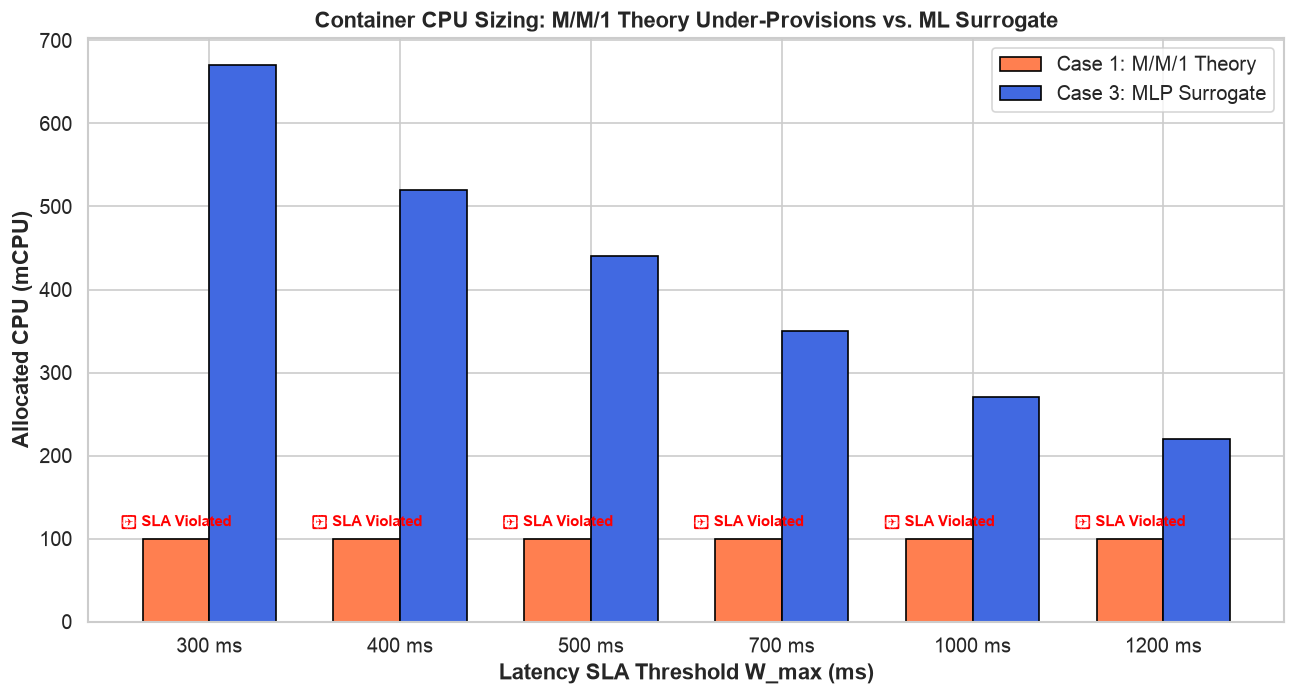

In [6]:
fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(comp_df))
width = 0.35

ax.bar(x - width/2, comp_df["MM1 CPU (mCPU)"], width, label="Case 1: M/M/1 Theory", color="coral", edgecolor="black")
ax.bar(x + width/2, comp_df["MLP CPU (mCPU)"], width, label="Case 3: MLP Surrogate", color="royalblue", edgecolor="black")

ax.set_xlabel("Latency SLA Threshold W_max (ms)", fontweight="bold")
ax.set_ylabel("Allocated CPU (mCPU)", fontweight="bold")
ax.set_title("Container CPU Sizing: M/M/1 Theory Under-Provisions vs. ML Surrogate", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([f"{w:.0f} ms" for w in comp_df["SLA (ms)"]])
ax.legend(loc="upper right")

for i in range(len(comp_df)):
    violated = not comp_df["MM1 Meets SLA?"].iloc[i]
    status = "❌ SLA Violated" if violated else "✓ OK"
    color = "red" if violated else "green"
    ax.text(x[i] - width/2, comp_df["MM1 CPU (mCPU)"].iloc[i] + 15, status, ha="center", fontsize=9, color=color, fontweight="bold")

plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "10_mm1_vs_mlp_empirical_showdown.png"), dpi=150, bbox_inches="tight")
plt.show()

## 5. Summary & Engineering Takeaways

1. **Why Pure Queueing Theory Fails in Modern Containers:**
   M/M/1 assumes smooth Poisson arrivals and infinite CPU sharing. In containerized clouds, Linux CFS enforces quota buckets per $100\text{ ms}$. If a container exhausts its CPU quota mid-period, execution stops entirely until the next epoch, leading to **massive latency degradation** that queueing formulas cannot foresee.

2. **The Power of Neural Network Surrogates (MLP):**
   The MLP neural network acts as a differentiable, highly accurate ($R^2 > 0.95$) digital twin of the container, learning both the normal operation zone and the latency cliff.

3. **Production Cloud Recommendation:**
   Production autoscalers (such as Kubernetes Vertical Pod Autoscaler or custom control loops) should integrate data-driven surrogate models trained on empirical cluster telemetry to prevent catastrophic SLA violations under heavy loads.
